Using device: cuda

Training Logistic Regression...

--- Logistic Regression Results ---
Accuracy: 0.8780 | Precision: 0.8574 | Recall: 0.9071 | F1-Score: 0.8816

Training LSTM...
LSTM - Epoch 1/4 completed.
LSTM - Epoch 2/4 completed.
LSTM - Epoch 3/4 completed.
LSTM - Epoch 4/4 completed.

--- LSTM Results ---
Accuracy: 0.6515 | Precision: 0.6317 | Recall: 0.7283 | F1-Score: 0.6766

Training Vanilla Transformer...
Vanilla Transformer - Epoch 1/4 completed.
Vanilla Transformer - Epoch 2/4 completed.
Vanilla Transformer - Epoch 3/4 completed.
Vanilla Transformer - Epoch 4/4 completed.

--- Vanilla Transformer Results ---
Accuracy: 0.8130 | Precision: 0.7944 | Recall: 0.8452 | F1-Score: 0.8190

Preparing & Fine-tuning Pretrained BERT...


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT - Epoch 1/2 completed.
BERT - Epoch 2/2 completed.

--- Pretrained BERT Results ---
Accuracy: 0.8815 | Precision: 0.8946 | Recall: 0.8651 | F1-Score: 0.8796

================ COMPARATIVE SUMMARY ================
                     Accuracy  Precision    Recall  F1-Score
Logistic Regression    0.8780   0.857413  0.907093  0.881553
LSTM                   0.6515   0.631716  0.728272  0.676566
Vanilla Transformer    0.8130   0.794366  0.845155  0.818974
Pretrained BERT        0.8815   0.894628  0.865135  0.879634


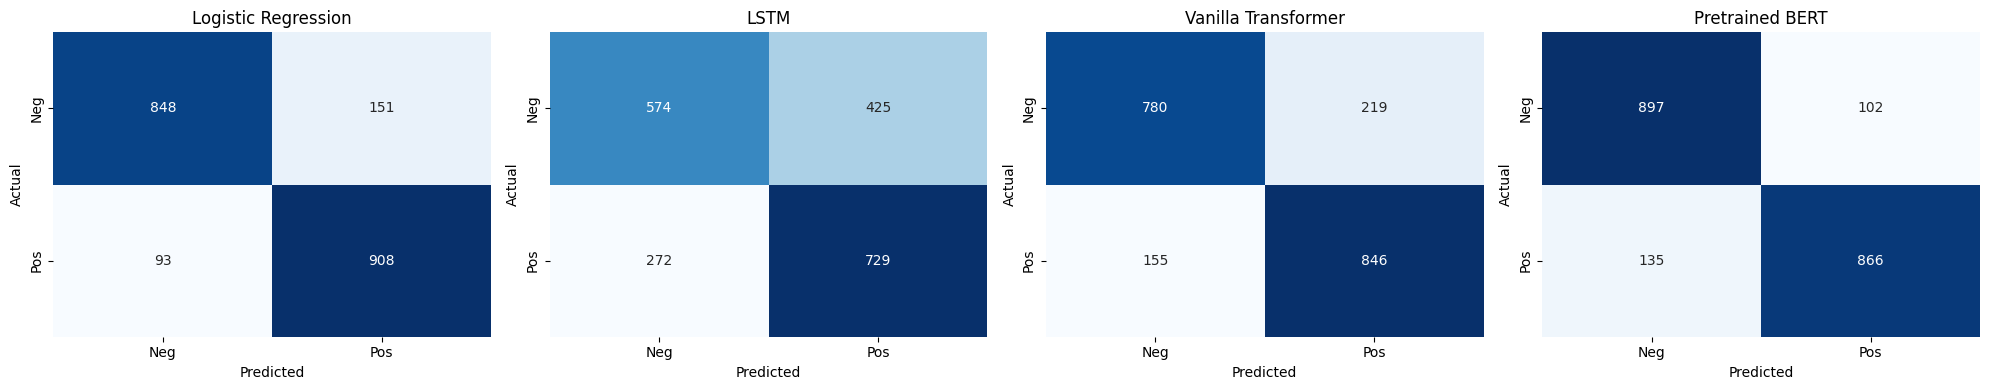

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from collections import Counter

from transformers import BertTokenizer, BertForSequenceClassification
from torch.optim import AdamW

# Set random seeds and device
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# ==========================================
# 1. DATA LOADING & PREPROCESSING
# ==========================================
# Load dataset (Ensure 'IMDB Dataset.csv' is in the current directory)
df = pd.read_csv('IMDB Dataset.csv')

df = df.sample(10000, random_state=SEED).reset_index(drop=True)

def clean_text(text):
    text = re.sub(r'<br\s*/?>', ' ', text)  # Remove HTML line breaks
    text = re.sub(r'[^a-zA-Z\s]', '', text) # Remove punctuation and numbers
    return text.lower().strip()

df['cleaned_review'] = df['review'].apply(clean_text)
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

X_train, X_test, y_train, y_test = train_test_split(
    df['cleaned_review'].values, df['label'].values, test_size=0.2, random_state=SEED
)

# Dictionary to store evaluation results
results = {}

def evaluate_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)

    results[name] = {
        'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1, 'CM': cm
    }
    print(f"\n--- {name} Results ---")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1-Score: {f1:.4f}")

# ==========================================
# 2. MODEL 1: LOGISTIC REGRESSION (TF-IDF)
# ==========================================
print("\nTraining Logistic Regression...")
tfidf = TfidfVectorizer(max_features=10000, stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)
lr_preds = lr_model.predict(X_test_tfidf)

evaluate_model("Logistic Regression", y_test, lr_preds)

# ==========================================
# VOCABULARY & PYTORCH DATASET FOR LSTM & TRANSFORMER
# ==========================================
MAX_VOCAB = 15000
MAX_LEN = 200
BATCH_SIZE = 64

# Build vocabulary
word_counts = Counter(" ".join(X_train).split())
vocab = {word: i+2 for i, (word, _) in enumerate(word_counts.most_common(MAX_VOCAB - 2))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

def encode_text(text):
    tokens = text.split()[:MAX_LEN]
    encoded = [vocab.get(w, 1) for w in tokens]
    return encoded + [0] * (MAX_LEN - len(encoded))

class IMDBDataset(Dataset):
    def __init__(self, texts, labels):
        self.X = torch.tensor([encode_text(t) for t in texts], dtype=torch.long)
        self.y = torch.tensor(labels, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(IMDBDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(IMDBDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

def train_and_eval_nn(model, name, epochs=3, lr=1e-3):
    model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        model.train()
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            out = model(X_b).squeeze(1)
            loss = criterion(out, y_b)
            loss.backward()
            optimizer.step()
        print(f"{name} - Epoch {epoch+1}/{epochs} completed.")

    model.eval()
    preds = []
    with torch.no_grad():
        for X_b, _ in test_loader:
            X_b = X_b.to(device)
            out = torch.sigmoid(model(X_b).squeeze(1))
            preds.extend((out >= 0.5).cpu().numpy())

    evaluate_model(name, y_test, np.array(preds))

# ==========================================
# 3. MODEL 2: LSTM
# ==========================================
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, 1)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))
        _, (hidden, _) = self.lstm(embedded)
        # Concatenate final forward and backward hidden states
        hidden_cat = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        return self.fc(self.dropout(hidden_cat))

print("\nTraining LSTM...")
lstm_model = SentimentLSTM(len(vocab))
train_and_eval_nn(lstm_model, "LSTM", epochs=4)

# ==========================================
# 4. MODEL 3: VANILLA TRANSFORMER
# ==========================================
class VanillaTransformer(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, num_heads=4, hidden_dim=256, num_layers=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.pos_embedding = nn.Embedding(MAX_LEN, embed_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dim_feedforward=hidden_dim, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc = nn.Linear(embed_dim, 1)

    def forward(self, x):
        positions = torch.arange(0, x.size(1), device=x.device).unsqueeze(0).expand_as(x)
        x = self.embedding(x) + self.pos_embedding(positions)
        x = self.transformer(x)
        x = x.mean(dim=1)  # Global average pooling over sequence length
        return self.fc(x)

print("\nTraining Vanilla Transformer...")
transformer_model = VanillaTransformer(len(vocab))
train_and_eval_nn(transformer_model, "Vanilla Transformer", epochs=4, lr=5e-4)

# ==========================================
# 5. MODEL 4: PRETRAINED BERT
# ==========================================
print("\nPreparing & Fine-tuning Pretrained BERT...")
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

class BERTDataset(Dataset):
    def __init__(self, texts, labels, max_len=128):
        self.encodings = tokenizer(
            list(texts), truncation=True, padding=True, max_length=max_len, return_tensors='pt'
        )
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

# Using a smaller batch size for BERT memory efficiency
bert_train_loader = DataLoader(BERTDataset(X_train, y_train), batch_size=16, shuffle=True)
bert_test_loader = DataLoader(BERTDataset(X_test, y_test), batch_size=32, shuffle=False)

bert_model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)
bert_model.to(device)
optimizer = AdamW(bert_model.parameters(), lr=2e-5)

# Fine-tune for 2 epochs
for epoch in range(2):
    bert_model.train()
    for batch in bert_train_loader:
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = bert_model(input_ids, attention_mask=attention_mask, labels=labels)
        outputs.loss.backward()
        optimizer.step()
    print(f"BERT - Epoch {epoch+1}/2 completed.")

bert_model.eval()
bert_preds = []
with torch.no_grad():
    for batch in bert_test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        outputs = bert_model(input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)
        bert_preds.extend(preds.cpu().numpy())

evaluate_model("Pretrained BERT", y_test, np.array(bert_preds))

# ==========================================
# 6. COMPARATIVE ANALYSIS & CONFUSION MATRICES
# ==========================================
summary_df = pd.DataFrame({
    model: {k: v for k, v in metrics.items() if k != 'CM'}
    for model, metrics in results.items()
}).T

print("\n================ COMPARATIVE SUMMARY ================")
print(summary_df)

# Plot Confusion Matrices side-by-side
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, metrics) in zip(axes, results.items()):
    sns.heatmap(metrics['CM'], annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticklabels(['Neg', 'Pos'])
    ax.set_yticklabels(['Neg', 'Pos'])

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=300)
plt.show()